<a href="https://colab.research.google.com/github/prangunj23/CS163-Radio-Interferometry-Project/blob/main/Data_Generation_Aman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pyuvdata

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 75.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyuvdata]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from collections import defaultdict
folder_path = '/content/drive/MyDrive/CS 163/cs163_data/'
filetypes = defaultdict(int)
uv_files, cal_files = [], []
for filename in os.listdir(folder_path):
    if filename.endswith('.uvfits'):
        uv_files.append(os.path.join(folder_path, filename))
    elif filename.endswith('.calfits'):
        cal_files.append(os.path.join(folder_path, filename))

    filetypes[filename.split('.')[-1]] += 1

filetypes

Mounted at /content/drive


defaultdict(int, {'calfits': 10000, 'uvfits': 10000})

In [ ]:
from pyuvdata import UVCal
from pyuvdata import UVData
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import numpy as np

D = "/content/drive/MyDrive/CS 163/cs163_tensors"
X = np.load(f"{D}/X.npy", mmap_mode="r")   # observed visibilities (n, 2, 214, 214)
Y = np.load(f"{D}/Y.npy", mmap_mode="r")   # gains (n, 2, 214)
M = np.load(f"{D}/M.npy", mmap_mode="r")   # good antennas (n, 214)

n = 200                                                                # first 200 samples is plenty
V = X[:n, 0].astype(np.float32) + 1j * X[:n, 1].astype(np.float32)
g = Y[:n, 0] + 1j * Y[:n, 1]
G = g[:, :, None] * g.conj()[:, None, :]                               # g_i * conj(g_j)
ok = M[:n, :, None] & M[:n, None, :] & ~np.eye(214, dtype=bool)       # good pairs, no autos

def similarity(sky):
    """Every sample is the same sky, so after correct calibration this should be ~1."""
    sky = np.where(ok, sky, 0)
    sky = sky / np.linalg.norm(sky.reshape(n, -1), axis=1)[:, None, None]
    ref = sky.mean(0)
    return np.abs((sky * ref.conj()).sum((1, 2))).mean() / np.linalg.norm(ref)

with np.errstate(divide="ignore", invalid="ignore"):
    print("no calibration  :", round(similarity(V), 3))
    print("divide   (V / G):", round(similarity(V / G), 3))
    print("multiply (V * G):", round(similarity(V * G), 3))

no calibration  : 0.071
divide   (V / G): 0.072
multiply (V * G): 0.99


In [ ]:
def similarity(a, ref):
    """How much each sample looks like the reference sky (1 = identical, ~0 = unrelated)."""
    a2 = a.reshape(len(a), -1); r = ref.ravel()
    return np.abs(a2 @ r.conj()) / (np.linalg.norm(a2, axis=1) * np.linalg.norm(r))

def calibrate_both(s, e):
    V = X[s:e, 0].astype(np.float32) + 1j * X[s:e, 1].astype(np.float32)
    g = Y[s:e, 0] + 1j * Y[s:e, 1]
    G = g[:, :, None] * g.conj()[:, None, :]
    with np.errstate(divide="ignore", invalid="ignore"):
        return V * G, np.where(G != 0, V / G, 0)

# 1) reference sky from samples known to need multiply
# ref = calibrate_both(20, 120)[0].mean(0)

# # 2) test every sample both ways
# needs_divide = []
# for s in range(0, len(X), 250):
#     mul, div = calibrate_both(s, min(s + 250, len(X)))
#     needs_divide += list(s + np.where(similarity(div, ref) > similarity(mul, ref))[0])

# print("need divide  :", needs_divide)
# print("need multiply:", len(X) - len(needs_divide), "samples")

In [ ]:
# from numpy.lib.format import open_memmap
# A = "/content/drive/MyDrive/CS 163/cs163_calibrated"

# divide_set = set(needs_divide)          # {0, 10}
# n = len(X)

# # output file, same shape as X: (n, 2, 214, 214), real/imag split
# Xc = open_memmap(f"{A}/X_calibrated.npy", mode="w+",
#                  dtype=np.float32, shape=X.shape)

# for s in range(0, n, 250):
#     e = min(s + 250, n)
#     mul, div = calibrate_both(s, e)     # both versions for this chunk

#     # pick multiply by default, divide for the samples that need it
#     out = mul
#     for k in range(s, e):
#         if k in divide_set:
#             out[k - s] = div[k - s]

#     Xc[s:e, 0] = out.real               # store real part
#     Xc[s:e, 1] = out.imag               # store imaginary part

# Xc.flush()
# print("saved", Xc.shape)

In [ ]:
A = "/content/drive/MyDrive/CS 163/cs163_calibrated"
calibrated_tensor = np.load(f"{A}/X_calibrated.npy", mmap_mode="r")

In [ ]:
uvd = UVData.from_file('/content/drive/MyDrive/CS 163/cs163_data/uncalib_data_100.uvfits')
lam = 299792458 / uvd.freq_array.ravel()[0]
u_all = uvd.uvw_array[:, 0] / lam
v_all = uvd.uvw_array[:, 1] / lam
ants = np.union1d(uvd.ant_1_array, uvd.ant_2_array)          # same antenna order as the tensors
bi = np.searchsorted(ants, uvd.ant_1_array)
bj = np.searchsorted(ants, uvd.ant_2_array)

def sky_image(u, v, vis, grid_size=256):
    """Grid visibilities onto the uv-plane and inverse-FFT to a dirty image."""
    max_uv = max(np.max(np.abs(u)), np.max(np.abs(v)))
    uv_grid = np.zeros((grid_size, grid_size), dtype=complex)
    bins = np.linspace(-max_uv, max_uv, grid_size)
    ui = np.clip(np.digitize(u, bins) - 1, 0, grid_size - 1)
    vi = np.clip(np.digitize(v, bins) - 1, 0, grid_size - 1)
    np.add.at(uv_grid, (vi, ui), vis)
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(uv_grid)))

In [ ]:
D = "/content/drive/MyDrive/CS 163/cs163_tensors"
X = np.load(f"{D}/X.npy", mmap_mode="r")   # observed visibilities (n, 2, 214, 214)
Y = np.load(f"{D}/Y.npy", mmap_mode="r")   # gains (n, 2, 214)

def tensor_vis(k):
    V = X[k, 0].astype(np.float32) + 1j * X[k, 1].astype(np.float32)
    g = Y[k, 0] + 1j * Y[k, 1]
    vis = V[bi, bj]                        # one value per baseline, matches u_all / v_all
    G = g[bi] * np.conj(g[bj])             # g_i * conj(g_j)
    with np.errstate(divide="ignore", invalid="ignore"):
        divided = np.where(G != 0, vis / G, 0)
    return [vis, divided, vis * G]

# titles = ['Uncorrected', 'Divide by g_i g_j* (old)', 'Multiply by g_i g_j* (fix)']
# samples = [0, 10]
# fig, ax = plt.subplots(len(samples), 3, figsize=(20, 5.5 * len(samples)))
# for row, k in zip(ax, samples):
#     for a, vis, title in zip(row, tensor_vis(k), titles):
#         im = a.imshow(np.abs(sky_image(u_all, v_all, vis)), extent=[-1, 1, -1, 1],
#                       cmap='hot', origin='lower')
#         a.set(title=f'Sample {k}: {title}', xlabel='Relative RA', ylabel='Relative Dec')
#         plt.colorbar(im, ax=a, label='Intensity')
# plt.tight_layout()
# plt.savefig('tensor_divide_vs_multiply.png', dpi=300)
# plt.show()

In [ ]:
calibrated_tensor = np.load(f"{A}/X_calibrated.npy", mmap_mode="r")

def three_vis(k):
    V = X[k, 0].astype(np.float32) + 1j * X[k, 1].astype(np.float32)
    g = Y[k, 0] + 1j * Y[k, 1]
    G = g[bi] * np.conj(g[bj])
    C = calibrated_tensor[k, 0].astype(np.float32) + 1j * calibrated_tensor[k, 1].astype(np.float32)
    return [V[bi, bj], C[bi, bj], V[bi, bj] * G]

# titles = ['Uncorrected (X)', 'X_calibrated', 'Multiply by g_i g_j* (reference)']
# samples = [0, 10]
# fig, ax = plt.subplots(len(samples), 3, figsize=(20, 5.5 * len(samples)))
# for row, k in zip(ax, samples):
#     for a, vis, title in zip(row, three_vis(k), titles):
#         im = a.imshow(np.abs(sky_image(u_all, v_all, vis)), extent=[-1, 1, -1, 1],
#                       cmap='hot', origin='lower')
#         a.set(title=f'Sample {k}: {title}', xlabel='Relative RA', ylabel='Relative Dec')
#         plt.colorbar(im, ax=a, label='Intensity')
# plt.tight_layout()
# plt.savefig('calibrated_tensor_check.png', dpi=300)
# plt.show()

In [ ]:
# ref = (calibrated_tensor[20:120, 0].astype(np.float32) + 1j * calibrated_tensor[20:120, 1].astype(np.float32)).mean(0)
# bad = []
# for s in range(0, len(calibrated_tensor), 250):
#     C = calibrated_tensor[s:s+250, 0].astype(np.float32) + 1j * calibrated_tensor[s:s+250, 1].astype(np.float32)
#     bad += list(s + np.where(similarity(C, ref) < 0.9)[0])
# print("samples that don't match the sky:", bad)

The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)


baselines used: 0.9917459487915039
epoch  0  train 0.4744  val 0.3415
epoch  1  train 0.1513  val 0.0993
epoch  2  train 0.0525  val 0.0689
epoch  3  train 0.0341  val 0.0594
epoch  4  train 0.0278  val 0.0577
epoch  5  train 0.0248  val 0.0542
epoch  6  train 0.0228  val 0.0549
epoch  7  train 0.0217  val 0.0537
epoch  8  train 0.0210  val 0.0551
epoch  9  train 0.0205  val 0.0539
epoch 10  train 0.0202  val 0.0558
epoch 11  train 0.0198  val 0.0537
epoch 12  train 0.0197  val 0.0536
epoch 13  train 0.0206  val 0.0553
epoch 14  train 0.0211  val 0.0564

TEST pair loss (lower is better)
  no calibration (g = 1): 2.0195
  predict zeros         : 1.0197
  classical eigenvector : 0.0002
  RowNet (ours)         : 0.0556


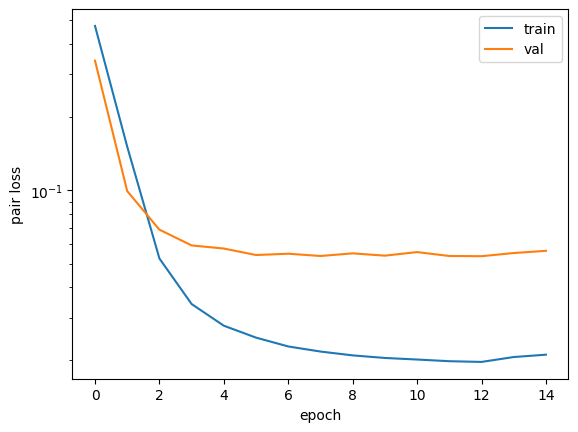

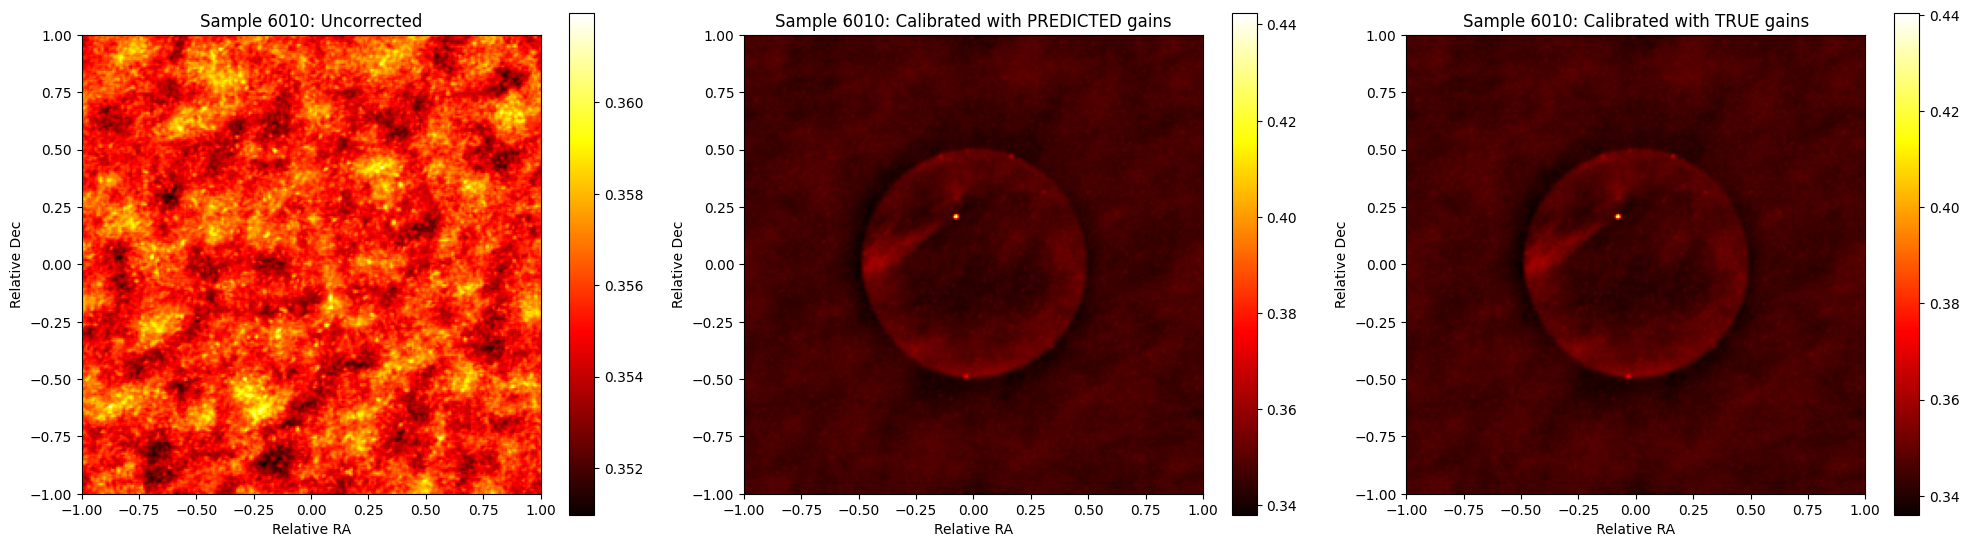

In [ ]:
import torch, torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
N = 214

# ---------------- data: drop samples 0 and 10, split 8000 / 1000 / rest ----------------
keep = np.setdiff1d(np.arange(len(X)), [0, 10])
np.random.default_rng(0).shuffle(keep)
tr, va, te = keep[:8000], keep[8000:9000], keep[9000:]

Xt = torch.from_numpy(np.ascontiguousarray(X)).to(device)          # ~1.8 GB, fp16
Yt = torch.from_numpy(np.ascontiguousarray(Y)).to(device)
Mt = torch.from_numpy(np.ascontiguousarray(M)).to(device)

# ---------------- the one shared sky, from TRAIN samples only ----------------
C = calibrated_tensor[np.sort(tr[:500])]
sky = torch.from_numpy((C[:, 0].astype(np.float32) + 1j * C[:, 1].astype(np.float32)).mean(0)).to(device)
off = ~torch.eye(N, dtype=torch.bool, device=device)
use = off & (sky.abs() > 0.1 * sky.abs()[off].median())             # skip baselines where the sky is ~0
print("baselines used:", use.float().mean().item())

def ratio(ids):
    """R_ij = sky_ij / X_ij  ≈  g_i * conj(g_j)   (because X = sky / (g_i conj(g_j)))"""
    x = Xt[ids].float()
    V = torch.complex(x[:, 0], x[:, 1])
    return torch.where(use & (V.abs() > 1e-6), sky / V, 0)

def features(ids):                                                   # (B, N, 2N): antenna i's row of R
    R = ratio(ids)
    return torch.cat([R.real, R.imag], -1).clamp(-5, 5)

def true_gains(ids):
    y = Yt[ids]
    return torch.complex(y[:, 0], y[:, 1]), Mt[ids]

# ---------------- model: one small MLP shared by all antennas ----------------
class RowNet(nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * N, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 2))
    def forward(self, f):                                            # f: (B, N, 2N)
        out = self.net(f)
        return torch.complex(out[..., 0], out[..., 1])               # (B, N) complex gains

def pair_loss(gp, gt, m):
    """Compare g_i conj(g_j) for every pair -> ignores the unknowable global phase."""
    w = (m[:, :, None] & m[:, None, :] & off).float()
    d = gp[:, :, None] * gp.conj()[:, None, :] - gt[:, :, None] * gt.conj()[:, None, :]
    return (d.abs() ** 2 * w).sum() / w.sum()

@torch.no_grad()
def evaluate(predict, ids, bs=128):
    tot = 0
    for s in range(0, len(ids), bs):
        b = ids[s:s + bs]; gt, m = true_gains(b)
        tot += pair_loss(predict(b), gt, m).item() * len(b)
    return tot / len(ids)

# ---------------- baselines ----------------
ones  = lambda b: torch.ones(len(b), N, dtype=torch.complex64, device=device)     # no calibration
zeros = lambda b: torch.zeros(len(b), N, dtype=torch.complex64, device=device)

def eigen(b):                                                        # classical: R is rank-1 -> top eigenvector
    R = ratio(b); R = (R + R.conj().transpose(1, 2)) / 2
    _, U = torch.linalg.eigh(R)
    g = U[:, :, -1]
    return g / g.abs().mean(1, keepdim=True)

# ---------------- train ----------------
model = RowNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
hist = {"train": [], "val": []}
for ep in range(15):
    perm = np.random.permutation(tr); losses = []
    for s in range(0, len(perm), 64):
        b = perm[s:s + 64]; gt, m = true_gains(b)
        loss = pair_loss(model(features(b)), gt, m)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    model.eval(); hist["train"].append(np.mean(losses))
    hist["val"].append(evaluate(lambda b: model(features(b)), va)); model.train()
    print(f"epoch {ep:2d}  train {hist['train'][-1]:.4f}  val {hist['val'][-1]:.4f}")

model.eval()
print("\nTEST pair loss (lower is better)")
print(f"  no calibration (g = 1): {evaluate(ones, te):.4f}")
print(f"  predict zeros         : {evaluate(zeros, te):.4f}")
print(f"  classical eigenvector : {evaluate(eigen, te):.4f}")
print(f"  RowNet (ours)         : {evaluate(lambda b: model(features(b)), te):.4f}")

plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("pair loss"); plt.legend(); plt.show()

# ---------------- picture: calibrate one test sample with the PREDICTED gains ----------------
k = int(te[0])
with torch.no_grad():
    gp = model(features(np.array([k])))[0].cpu().numpy()
gt = Y[k, 0] + 1j * Y[k, 1]
V = X[k, 0].astype(np.float32) + 1j * X[k, 1].astype(np.float32)
vis = V[bi, bj]
panels = [vis, vis * gp[bi] * np.conj(gp[bj]), vis * gt[bi] * np.conj(gt[bj])]
titles = ['Uncorrected', 'Calibrated with PREDICTED gains', 'Calibrated with TRUE gains']
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for a, p, t in zip(ax, panels, titles):
    im = a.imshow(np.abs(sky_image(u_all, v_all, p)), extent=[-1, 1, -1, 1], cmap='hot', origin='lower')
    a.set(title=f'Sample {k}: {t}', xlabel='Relative RA', ylabel='Relative Dec'); plt.colorbar(im, ax=a)
plt.tight_layout(); plt.savefig('rownet_calibration.png', dpi=300); plt.show()

training RowNet
  step    0  loss 1.0206
  step  500  loss 0.7136
  step 1000  loss 0.5015
  step 1500  loss 0.4257
  step 2000  loss 0.4310
  step 2500  loss 0.4327
training Transformer
  step    0  loss 1.3818
  step  500  loss 0.3948
  step 1000  loss 0.1870
  step 1500  loss 0.1287
  step 2000  loss 0.1155
  step 2500  loss 0.1019

eps      0.0    0.05     0.1     0.2     0.3     0.5
Classical eigenvector 0.0002  0.0007  0.0266  10.8631  101.0270  134.5206
RowNet                0.0459  0.0699  0.1290  0.3096  0.4988  0.8105
Transformer           0.0256  0.0266  0.0317  0.0480  0.0792  0.2161


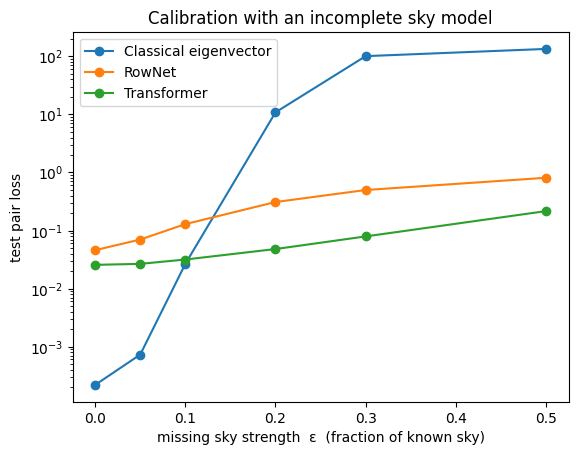

In [ ]:
import torch.nn as nn
NOISE, N_SRC, EPS_MAX = 0.01, 20, 0.5
ti, tj = torch.from_numpy(bi).to(device), torch.from_numpy(bj).to(device)

# ---------- baseline geometry: u, v for every antenna pair (214 x 214) ----------
Um = torch.zeros(N, N, device=device); Vm = torch.zeros(N, N, device=device)
Um[ti, tj] = torch.tensor(u_all, dtype=torch.float32, device=device); Um[tj, ti] = -Um[ti, tj]
Vm[ti, tj] = torch.tensor(v_all, dtype=torch.float32, device=device); Vm[tj, ti] = -Vm[ti, tj]
sky_norm  = sky[off].abs().pow(2).sum().sqrt()
sky_scale = sky[off].abs().mean()
all_good  = lambda B: torch.ones(B, N, dtype=torch.bool, device=device)

def make_batch(B, eps, gen):
    """True sky = our sky + random extra sources (strength eps). Methods only know our sky."""
    rnd = lambda *s: torch.rand(*s, generator=gen, device=device)
    rn  = lambda *s: torch.randn(*s, generator=gen, device=device)
    r, th = torch.sqrt(rnd(B, N_SRC)) * 0.9, rnd(B, N_SRC) * 2 * np.pi
    l, m = r * torch.cos(th), r * torch.sin(th)
    flux = -torch.log(rnd(B, N_SRC))
    phase = -2 * np.pi * (Um * l[..., None, None] + Vm * m[..., None, None])        # (B, src, N, N)
    extra = (flux[..., None, None] * torch.exp(1j * phase)).sum(1) * off
    extra = extra / extra.abs().pow(2).sum((1, 2), keepdim=True).sqrt() * sky_norm * eps[:, None, None]
    g = (1 + 0.1 * rn(B, N)) * torch.exp(1j * 2 * np.pi * rnd(B, N))
    G = g[:, :, None] * g.conj()[:, None, :]
    X_obs = (sky + extra) / G + NOISE * sky_scale * torch.complex(rn(B, N, N), rn(B, N, N))
    R = torch.where(use, sky / X_obs, 0)                    # built with the INCOMPLETE sky model
    return R, g

feat = lambda R: torch.cat([R.real, R.imag], -1).clamp(-5, 5)

def eigen_from_R(R):
    R = (R + R.conj().transpose(1, 2)) / 2
    g = torch.linalg.eigh(R)[1][:, :, -1]
    return g / g.abs().mean(1, keepdim=True)

class AntennaTransformer(nn.Module):
    """Each antenna's row of R is a token; attention lets antennas share information."""
    def __init__(self, d=128, layers=2, heads=4):
        super().__init__()
        self.inp = nn.Linear(2 * N, d)
        self.ant = nn.Parameter(0.02 * torch.randn(N, d))
        self.enc = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True), layers)
        self.out = nn.Linear(d, 2)
    def forward(self, f):
        o = self.out(self.enc(self.inp(f) + self.ant))
        return torch.complex(o[..., 0], o[..., 1])

def train(model, steps=3000, bs=32, lr=1e-3, seed=0):
    model.to(device).train(); opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator(device=device).manual_seed(seed)
    for step in range(steps):
        R, g = make_batch(bs, rnd_eps := torch.rand(bs, generator=gen, device=device) * EPS_MAX, gen)
        loss = pair_loss(model(feat(R)), g, all_good(bs))
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 500 == 0: print(f"  step {step:4d}  loss {loss.item():.4f}")
    return model.eval()

EPS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
@torch.no_grad()
def curve(predict, n_batches=8, bs=32):
    gen = torch.Generator(device=device).manual_seed(123)          # identical test data for every method
    out = []
    for e in EPS:
        losses = [pair_loss(predict(R), g, all_good(bs)).item()
                  for R, g in (make_batch(bs, torch.full((bs,), e, device=device), gen) for _ in range(n_batches))]
        out.append(np.mean(losses))
    return out

print("training RowNet");      rownet = train(RowNet(), lr=1e-3)
print("training Transformer"); transformer = train(AntennaTransformer(), lr=3e-4)

results = {
    "Classical eigenvector": curve(eigen_from_R),
    "RowNet":                curve(lambda R: rownet(feat(R))),
    "Transformer":           curve(lambda R: transformer(feat(R))),
}
print("\neps   " + "  ".join(f"{e:>6}" for e in EPS))
for name, vals in results.items():
    print(f"{name:22s}" + "  ".join(f"{v:6.4f}" for v in vals))

for name, vals in results.items():
    plt.plot(EPS, vals, "o-", label=name)
plt.yscale("log"); plt.xlabel("missing sky strength  ε  (fraction of known sky)")
plt.ylabel("test pair loss"); plt.title("Calibration with an incomplete sky model"); plt.legend()


eps      0.0    0.05     0.1     0.2     0.3     0.5
Classical eigenvector 0.0002  0.0007  0.0266  10.8631  101.0270  134.5206
RowNet                0.0459  0.0699  0.1290  0.3096  0.4988  0.8105
Transformer           0.0256  0.0266  0.0317  0.0480  0.0792  0.2161
Classical StEFCal     0.0000  0.0000  0.0002  0.0007  0.0017  0.0047


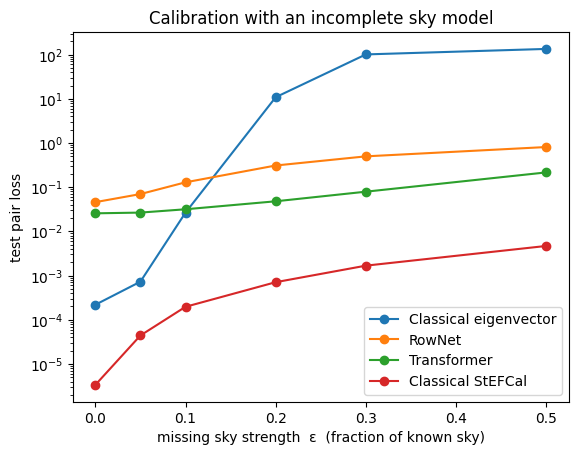

In [ ]:
def stefcal_from_R(R, iters=60):
    """Standard classical least-squares calibration on the observed data X (no ratios)."""
    w = use.float()
    X = torch.where(use, sky / R, 0)                         # recover the observed visibilities
    h = torch.ones(R.shape[:2], dtype=R.dtype, device=device)  # X = h_i conj(h_j) sky, with h = 1/g
    for k in range(iters):
        z = h.conj()[:, None, :] * sky
        h_new = (X * z.conj() * w).sum(2) / ((z.abs() ** 2) * w).sum(2).clamp(min=1e-12)
        h = h_new if k % 2 == 0 else (h_new + h) / 2
    return 1 / torch.where(h.abs() > 1e-6, h, torch.ones_like(h))

results["Classical StEFCal"] = curve(stefcal_from_R)
print("\neps   " + "  ".join(f"{e:>6}" for e in EPS))
for name, vals in results.items():
    print(f"{name:22s}" + "  ".join(f"{v:6.4f}" for v in vals))
for name, vals in results.items():
    plt.plot(EPS, vals, "o-", label=name)
plt.yscale("log"); plt.xlabel("missing sky strength  ε  (fraction of known sky)")
plt.ylabel("test pair loss"); plt.title("Calibration with an incomplete sky model"); plt.legend()

RowNet test pair loss: median 0.0254, mean 0.0556


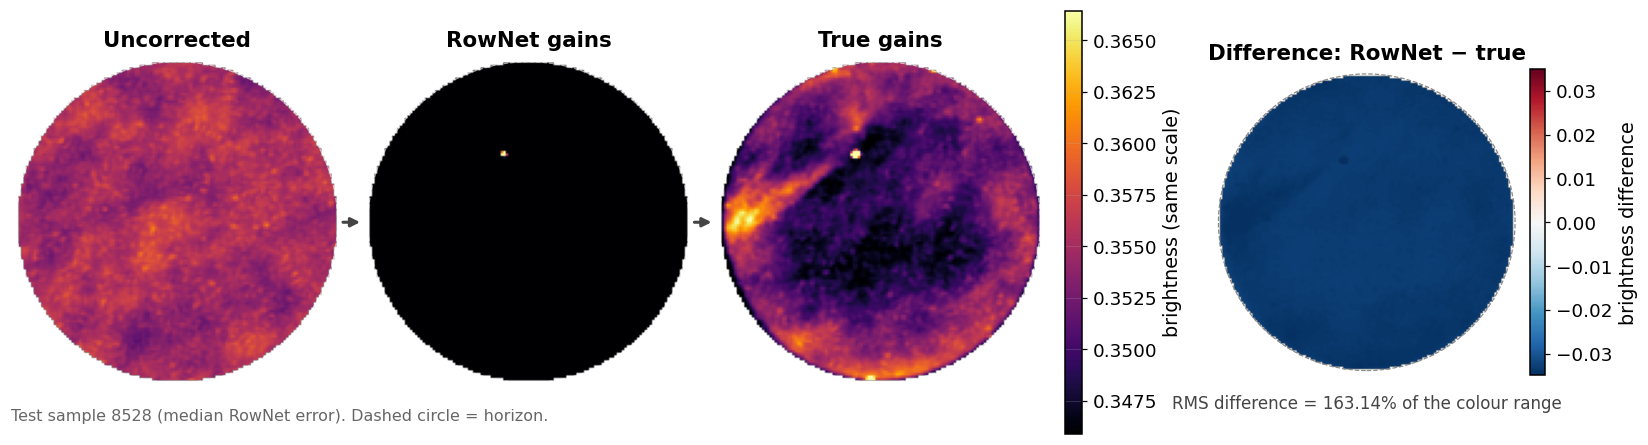

In [ ]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

OUT = "figs"; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 1.0,
    "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.7,
    "xtick.direction": "out", "ytick.direction": "out", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
})
# Same colours as the architecture diagram: orange = RowNet, blue = classical eigenvector
COL = {"RowNet": "#e07b39", "Transformer": "#7b4fb0",
       "Classical eigenvector": "#3b6fb6", "Classical StEFCal": "#222222"}
MEAN_RED = "#d62728"

def pair_loss_each(gp, gt, m):
    """Your pair_loss, but one number per sample instead of one per batch."""
    w = (m[:, :, None] & m[:, None, :] & off).float()
    d = gp[:, :, None] * gp.conj()[:, None, :] - gt[:, :, None] * gt.conj()[:, None, :]
    return (d.abs() ** 2 * w).sum((1, 2)) / w.sum((1, 2))

@torch.no_grad()
def per_sample_loss(predict, ids, bs=128):
    out = []
    for s in range(0, len(ids), bs):
        b = ids[s:s + bs]; gt, m = true_gains(b)
        out.append(pair_loss_each(predict(b), gt, m).cpu())
    return torch.cat(out).numpy()

model.eval()
rownet_pred = lambda b: model(features(b))
te_loss = per_sample_loss(rownet_pred, te)
print(f"RowNet test pair loss: median {np.median(te_loss):.4f}, mean {te_loss.mean():.4f}")

# %% ------------------------------------------------------------ 1. Image triptych + residual
# Pick a TYPICAL test sample (median RowNet error), so nobody can say it's cherry-picked.
k = int(te[np.argsort(te_loss)[len(te) // 2]])
with torch.no_grad():
    gp = model(features(np.array([k])))[0].cpu().numpy()
gt = Y[k, 0] + 1j * Y[k, 1]
V = X[k, 0].astype(np.float32) + 1j * X[k, 1].astype(np.float32)
vis = V[bi, bj]

GRID = 256
imgs = [np.abs(sky_image(u_all, v_all, p, GRID)) for p in
        (vis, vis * gp[bi] * np.conj(gp[bj]), vis * gt[bi] * np.conj(gt[bj]))]

# Real sky coordinates: the FFT image spans l in [-half, half]; the horizon is the circle l^2 + m^2 = 1
max_uv = max(np.abs(u_all).max(), np.abs(v_all).max())
half = (GRID - 1) / (4 * max_uv)
ax1d = np.linspace(-half, half, GRID)
keep = np.abs(ax1d) <= 1.05                                     # crop to just outside the horizon
L, Mg = np.meshgrid(ax1d[keep], ax1d[keep])
outside = L**2 + Mg**2 > 1.0
crop = lambda a: np.where(outside, np.nan, a[np.ix_(keep, keep)])
imgs = [crop(a) for a in imgs]
resid = imgs[1] - imgs[2]

vmin, vmax = np.nanpercentile(imgs[2], [1, 99.9])               # ONE colour scale, set by the true-gain image
rmax = np.nanpercentile(np.abs(resid), 99.5)              # ignore a few extreme pixels
err_pct = 100 * np.sqrt(np.nanmean(resid**2)) / (vmax - vmin)

ext = [ax1d[keep][0], ax1d[keep][-1]] * 2
fig = plt.figure(figsize=(18, 5.0))
gs = fig.add_gridspec(1, 6, width_ratios=[1, 1, 1, 0.05, 0.28, 1], wspace=0.08)
axs = [fig.add_subplot(gs[0, i]) for i in (0, 1, 2)]
cax = fig.add_subplot(gs[0, 3]); rax = fig.add_subplot(gs[0, 5])
titles = ["Uncorrected", "RowNet gains", "True gains"]
for a, im, t in zip(axs, imgs, titles):
    h = a.imshow(im, extent=ext, origin="lower", cmap="inferno", vmin=vmin, vmax=vmax)
    a.add_patch(Circle((0, 0), 1, fill=False, ec="white", lw=0.8, ls="--", alpha=0.6))
    a.set_title(t, fontweight="bold"); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    for sp in a.spines.values(): sp.set_visible(False)
for a in axs[:2]:
    a.annotate("", xy=(1.06, 0.5), xytext=(0.99, 0.5), xycoords="axes fraction",
               arrowprops=dict(arrowstyle="-|>", lw=2, color="#444"))
fig.colorbar(h, cax=cax, label="brightness (same scale)")
hr = rax.imshow(resid, extent=ext, origin="lower", cmap="RdBu_r", vmin=-rmax, vmax=rmax)
rax.add_patch(Circle((0, 0), 1, fill=False, ec="#888", lw=0.8, ls="--"))
rax.set_title("Difference: RowNet − true", fontweight="bold")
rax.set_xticks([]); rax.set_yticks([]); rax.grid(False)
for sp in rax.spines.values(): sp.set_visible(False)
fig.colorbar(hr, ax=rax, fraction=0.046, pad=0.03, label="brightness difference")
rax.text(0.5, -0.06, f"RMS difference = {err_pct:.2f}% of the colour range",
         transform=rax.transAxes, ha="center", va="top", fontsize=11, color="#444")
axs[0].text(0.0, -0.06, f"Test sample {k} (median RowNet error). Dashed circle = horizon.",
            transform=axs[0].transAxes, ha="left", va="top", fontsize=10.5, color="#666")
fig.savefig(f"{OUT}/1_image_triptych.png"); plt.show()


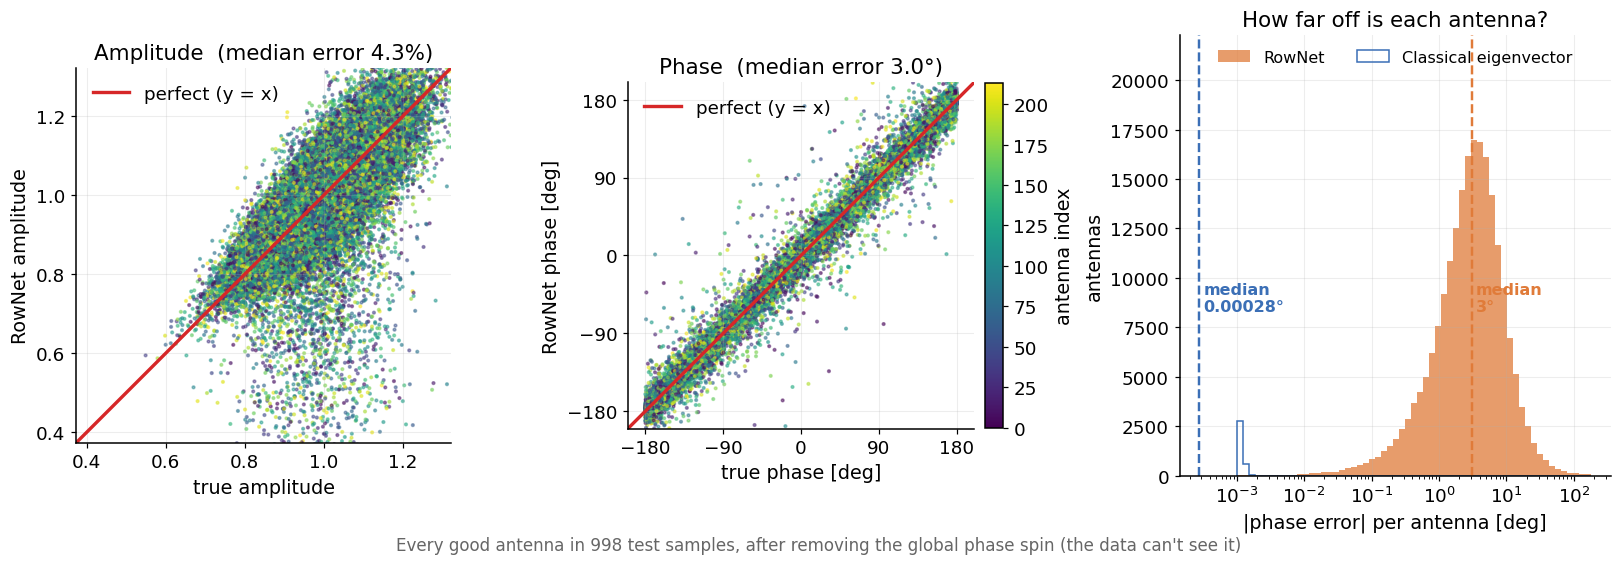

In [ ]:

# %% ------------------------------------------------------------ 2. Predicted vs true gains, per antenna
@torch.no_grad()
def aligned_gains(predict, ids, bs=128):
    """Predicted and true gains for every test antenna, after removing the one global phase spin."""
    P, T, Mk = [], [], []
    for s in range(0, len(ids), bs):
        b = ids[s:s + bs]; g_t, m = true_gains(b); g_p = predict(b)
        spin = torch.angle((g_t * g_p.conj() * m).sum(1, keepdim=True))
        P.append((g_p * torch.exp(1j * spin)).cpu()); T.append(g_t.cpu()); Mk.append(m.cpu())
    P, T, Mk = (torch.cat(a).numpy() for a in (P, T, Mk))
    return P, T, Mk

P, T, Mk = aligned_gains(rownet_pred, te)
Pe, _, _ = aligned_gains(eigen, te)

# colour each antenna by its distance from the array centre (like the reference figure's colourbar)
try:
    num2row = {a: r for r, a in enumerate(uvd.antenna_numbers)}
    pos = uvd.antenna_positions[[num2row[a] for a in ants]]
    radius = np.linalg.norm(pos - pos.mean(0), axis=1); rlab = "antenna distance from centre [m]"
except Exception:
    radius = np.arange(N, dtype=float); rlab = "antenna index"
R_all = np.broadcast_to(radius, P.shape)[Mk]

amp_t, amp_p = np.abs(T)[Mk], np.abs(P)[Mk]
dph = np.degrees(np.angle(P * T.conj()))[Mk]                     # phase error per antenna, in degrees
dph_e = np.degrees(np.angle(Pe * T.conj()))[Mk]
ph_t = np.degrees(np.angle(T))[Mk]; ph_p = ph_t + dph
amp_pct = 100 * np.median(np.abs(amp_p - amp_t) / amp_t)
med_ph, med_ph_e = np.median(np.abs(dph)), np.median(np.abs(dph_e))

order = np.random.default_rng(0).permutation(len(amp_t))[:60000]   # plenty of dots, quick to draw
fig, axs = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw=dict(width_ratios=[1, 1, 1.15], wspace=0.45))
for a, x, y, lab, unit in [(axs[0], amp_t, amp_p, "amplitude", ""), (axs[1], ph_t, ph_p, "phase", " [deg]")]:
    sc = a.scatter(x[order], y[order], c=R_all[order], s=3, alpha=0.5, cmap="viridis", rasterized=True)
    lim = list(np.percentile(np.r_[x, y], [0.2, 99.8])) if lab == "amplitude" else [-200, 200]
    a.plot(lim, lim, color=MEAN_RED, lw=2.2, label="perfect (y = x)")
    a.set_xlabel(f"true {lab}{unit}"); a.set_ylabel(f"RowNet {lab}{unit}")
    a.set_xlim(lim); a.set_ylim(lim); a.set_aspect("equal"); a.legend(loc="upper left")
axs[1].set_xticks([-180, -90, 0, 90, 180]); axs[1].set_yticks([-180, -90, 0, 90, 180])
axs[0].set_title(f"Amplitude  (median error {amp_pct:.1f}%)")
axs[1].set_title(f"Phase  (median error {med_ph:.1f}°)")
cb = fig.colorbar(sc, ax=axs[1], fraction=0.046, pad=0.03); cb.set_label(rlab); cb.solids.set_alpha(1)

bins = np.logspace(np.log10(max(1e-3, np.percentile(np.abs(dph_e), 0.5))), np.log10(180), 60)
axs[2].hist(np.abs(dph), bins=bins, color=COL["RowNet"], alpha=0.75, label="RowNet")
axs[2].hist(np.abs(dph_e), bins=bins, histtype="step", lw=2, color=COL["Classical eigenvector"],
            label="Classical eigenvector")
for v, c in [(med_ph, COL["RowNet"]), (med_ph_e, COL["Classical eigenvector"])]:
    axs[2].axvline(v, color=c, ls="--", lw=1.6)
    axs[2].text(v * 1.15, axs[2].get_ylim()[1] * 0.55, f"median\n{v:.2g}°", color=c, fontsize=10.5,
                fontweight="bold", va="top")
axs[2].set_xscale("log"); axs[2].set_xlabel("|phase error| per antenna [deg]"); axs[2].set_ylabel("antennas")
axs[2].set_title("How far off is each antenna?"); axs[2].set_ylim(0, axs[2].get_ylim()[1] * 1.25)
axs[2].legend(loc="upper center", ncol=2, fontsize=10.5)
fig.text(0.5, -0.02, f"Every good antenna in {len(te)} test samples, after removing the global phase spin "
         "(the data can't see it)", ha="center", fontsize=11, color="#666")
fig.savefig(f"{OUT}/2_gains_pred_vs_true.png"); plt.show()


Text(0, 0.5, 'avg amplitude error')

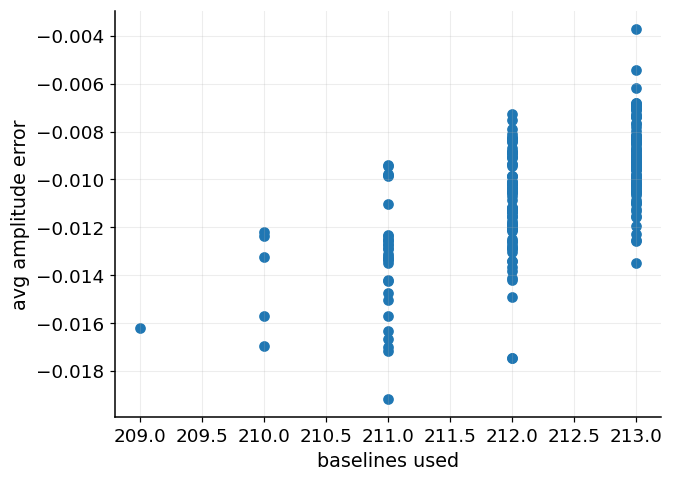

In [ ]:
n_used = use.sum(1).cpu().numpy()                        # baselines kept per antenna
amp_err = (np.abs(P) / np.abs(T) - 1).mean(0)           # avg amplitude error per antenna
plt.scatter(n_used, amp_err); plt.xlabel("baselines used"); plt.ylabel("avg amplitude error")

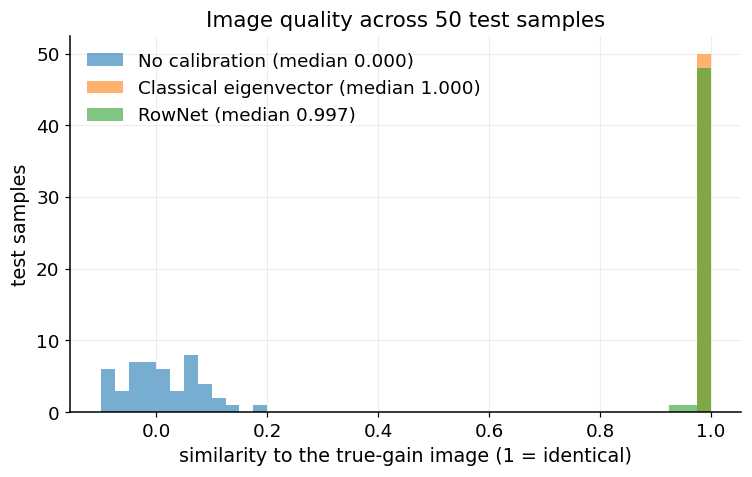

In [ ]:
def img_from_gains(k, g):
    """Dirty image of test sample k after correcting with gains g (multiply convention)."""
    V = X[k, 0].astype(np.float32) + 1j * X[k, 1].astype(np.float32)
    vis = V[bi, bj] * g[bi] * np.conj(g[bj])
    return np.abs(sky_image(u_all, v_all, vis))

def match(a, b):
    """Image similarity: correlation of pixel brightness (1 = identical, 0 = unrelated)."""
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]

ks = te[:50]
with torch.no_grad():
    G_net = model(features(ks)).cpu().numpy()       # RowNet gains
    G_eig = eigen(ks).cpu().numpy()                 # classical eigenvector gains
G_true = Y[ks, 0] + 1j * Y[ks, 1]

scores = {"No calibration": [], "Classical eigenvector": [], "RowNet": []}
for n, k in enumerate(ks):
    ref = img_from_gains(k, G_true[n])              # the "perfect" image
    scores["No calibration"].append(match(img_from_gains(k, np.ones(N)), ref))
    scores["Classical eigenvector"].append(match(img_from_gains(k, G_eig[n]), ref))
    scores["RowNet"].append(match(img_from_gains(k, G_net[n]), ref))

plt.figure(figsize=(7, 4.5))
bins = np.linspace(-0.1, 1, 45)
for name, s in scores.items():
    plt.hist(s, bins=bins, alpha=0.6, label=f"{name} (median {np.median(s):.3f})")
plt.xlabel("similarity to the true-gain image (1 = identical)")
plt.ylabel("test samples")
plt.title("Image quality across 50 test samples")
plt.legend(); plt.tight_layout(); plt.savefig("image_similarity_hist.png", dpi=300); plt.show()

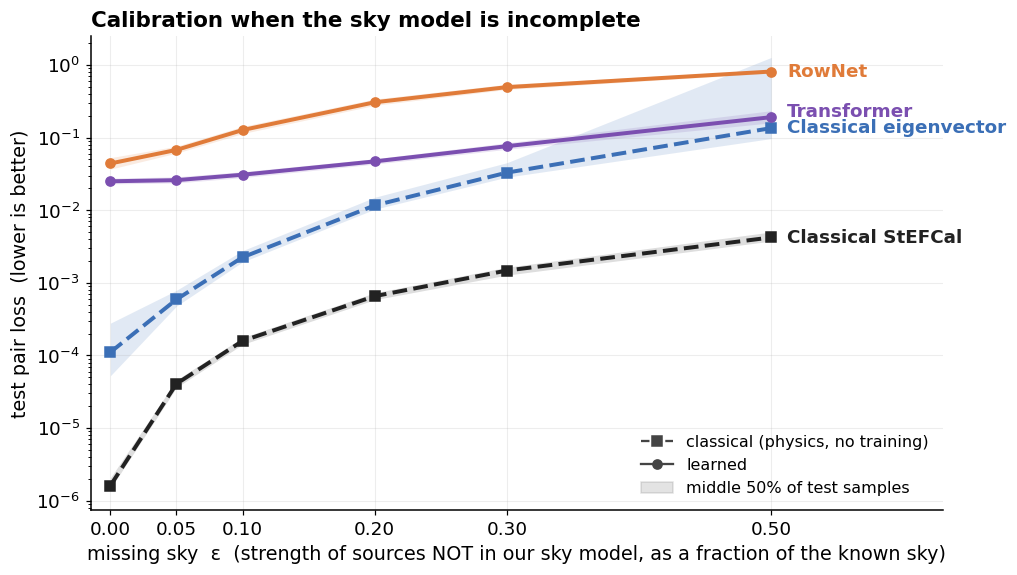

In [ ]:

# %% ------------------------------------------------------------ 3. Incomplete sky model, restyled
@torch.no_grad()
def curve_spread(predict, n_batches=8, bs=32):
    """Like your curve(), but keeps every test sample's loss so we can draw a spread band."""
    gen = torch.Generator(device=device).manual_seed(123)          # identical test data for every method
    out = []
    for e in EPS:
        per = [pair_loss_each(predict(R), g, all_good(bs)).cpu().numpy()
               for R, g in (make_batch(bs, torch.full((bs,), e, device=device), gen) for _ in range(n_batches))]
        out.append(np.concatenate(per))
    return np.array(out)                                            # (len(EPS), n_batches * bs)

methods = {
    "Classical StEFCal":     stefcal_from_R,
    "Classical eigenvector": eigen_from_R,
    "RowNet":                lambda R: rownet(feat(R)),
    "Transformer":           lambda R: transformer(feat(R)),
}
spread = {name: curve_spread(f) for name, f in methods.items()}
STAT = np.median     # line = median test sample. Use np.mean to match the numbers in your printed table.
eps = np.array(EPS)

fig, ax = plt.subplots(figsize=(10, 5.6)); ends = {}
for name, S in spread.items():
    med, lo, hi = STAT(S, 1), np.percentile(S, 25, 1), np.percentile(S, 75, 1)
    classical = name.startswith("Classical")
    ax.fill_between(eps, lo, hi, color=COL[name], alpha=0.15, lw=0)
    ax.plot(eps, med, ls="--" if classical else "-", marker="s" if classical else "o",
            ms=6, lw=2.6, color=COL[name])
    ends[name] = med[-1]

# name each line at its right end, nudged apart so labels never overlap (log spacing)
ys = sorted(ends.items(), key=lambda t: t[1]); placed = []
for name, y in ys:
    ly = np.log10(y)
    if placed and ly - placed[-1] < 0.22: ly = placed[-1] + 0.22
    placed.append(ly)
    ax.text(eps[-1] + 0.012, 10**ly, name, color=COL[name], va="center", fontsize=12, fontweight="bold")

# where the Transformer starts beating the eigenvector method
m_tr, m_eig = STAT(spread["Transformer"], 1), STAT(spread["Classical eigenvector"], 1)
cross = next((e for e, a, b in zip(eps, m_tr, m_eig) if a < b), None)
if cross is not None:
    ax.axvspan(cross, eps[-1], color="#f2f2f2", zorder=0)
    ax.text(cross + 0.008, 0.97, f"ε ≥ {cross:g}: the learned models beat the\neigenvector method, "
            "which falls apart", transform=ax.get_xaxis_transform(), va="top", fontsize=10.5, color="#555")
ax.set_yscale("log"); ax.set_xlim(eps[0] - 0.015, eps[-1] + 0.13)
ax.set_xticks(eps)
ax.set_xlabel("missing sky  ε  (strength of sources NOT in our sky model, as a fraction of the known sky)")
ax.set_ylabel("test pair loss  (lower is better)")
ax.set_title("Calibration when the sky model is incomplete", fontweight="bold", loc="left")
ax.legend(handles=[Line2D([], [], color="#444", ls="--", marker="s", label="classical (physics, no training)"),
                   Line2D([], [], color="#444", ls="-", marker="o", label="learned"),
                   plt.Rectangle((0, 0), 1, 1, color="#444", alpha=0.15, label="middle 50% of test samples")],
          loc="lower right", fontsize=10.5)
fig.savefig(f"{OUT}/3_incomplete_sky.png"); plt.show()


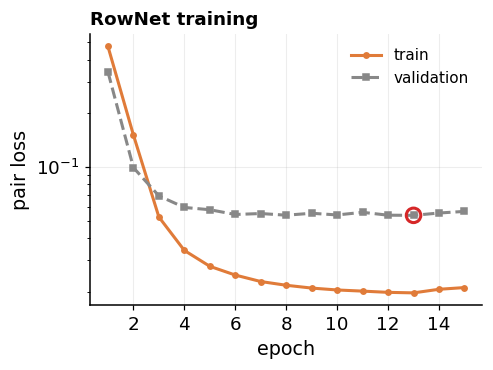

In [ ]:

# %% ------------------------------------------------------------ 4. Small training curve (corner inset / backup)
ep = np.arange(1, len(hist["train"]) + 1)
best = int(np.argmin(hist["val"]))
fig, ax = plt.subplots(figsize=(4.6, 3.2))
ax.plot(ep, hist["train"], "-o", ms=3.5, lw=2, color=COL["RowNet"], label="train")
ax.plot(ep, hist["val"], "--s", ms=3.5, lw=2, color="#888", label="validation")
ax.scatter(ep[best], hist["val"][best], s=90, facecolor="none", edgecolor=MEAN_RED, lw=2, zorder=5)
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("pair loss")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("RowNet training", fontsize=12, fontweight="bold", loc="left"); ax.legend(fontsize=10)
fig.savefig(f"{OUT}/4_training_curve_small.png"); plt.show()

# %% ------------------------------------------------------------ 5. Download all figures
# import shutil; from google.colab import files
# shutil.make_archive("figs", "zip", OUT); files.download("figs.zip")

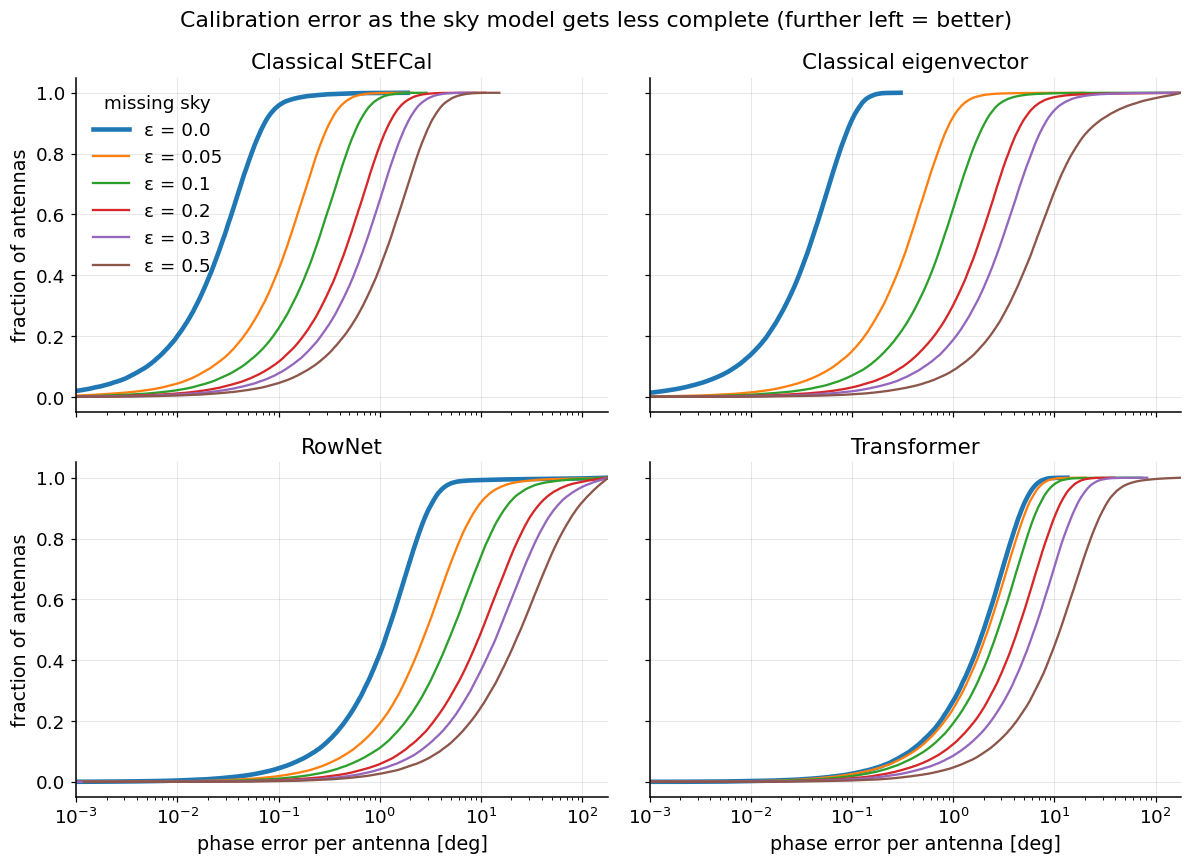

In [ ]:
@torch.no_grad()
def phase_errors(predict, eps, n_batches=8, bs=32):
    """Phase error (degrees) for every antenna in the test batches at one epsilon."""
    gen = torch.Generator(device=device).manual_seed(123)          # same test data for every method
    errs = []
    for _ in range(n_batches):
        R, g = make_batch(bs, torch.full((bs,), eps, device=device), gen)
        gp = predict(R)
        spin = torch.angle((g * gp.conj()).sum(1, keepdim=True))   # remove the unknowable global phase
        err = torch.angle(gp * torch.exp(1j * spin) * g.conj())    # leftover phase error per antenna
        errs.append(torch.rad2deg(err).abs().flatten().cpu())
    return torch.cat(errs).numpy()

methods = {
    "Classical StEFCal":     stefcal_from_R,
    "Classical eigenvector": eigen_from_R,
    "RowNet":                lambda R: rownet(feat(R)),
    "Transformer":           lambda R: transformer(feat(R)),
}

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, (name, predict) in zip(axs.flat, methods.items()):
    for e in EPS:
        err = np.sort(phase_errors(predict, e))
        frac = np.arange(1, len(err) + 1) / len(err)                # fraction of antennas at or below each error
        ax.plot(err, frac, lw=3 if e == 0 else 1.5, label=f"ε = {e}")
    ax.set_title(name)
    ax.set_xscale("log")
    ax.set_xlim(1e-3, 180)
    ax.grid(alpha=0.3)
for ax in axs[1]: ax.set_xlabel("phase error per antenna [deg]")
for ax in axs[:, 0]: ax.set_ylabel("fraction of antennas")
axs[0, 0].legend(title="missing sky", loc="upper left")
fig.suptitle("Calibration error as the sky model gets less complete (further left = better)")
fig.tight_layout()
fig.savefig("incomplete_sky_2x2.png", dpi=300)
plt.show()

training RowNet
training Transformer


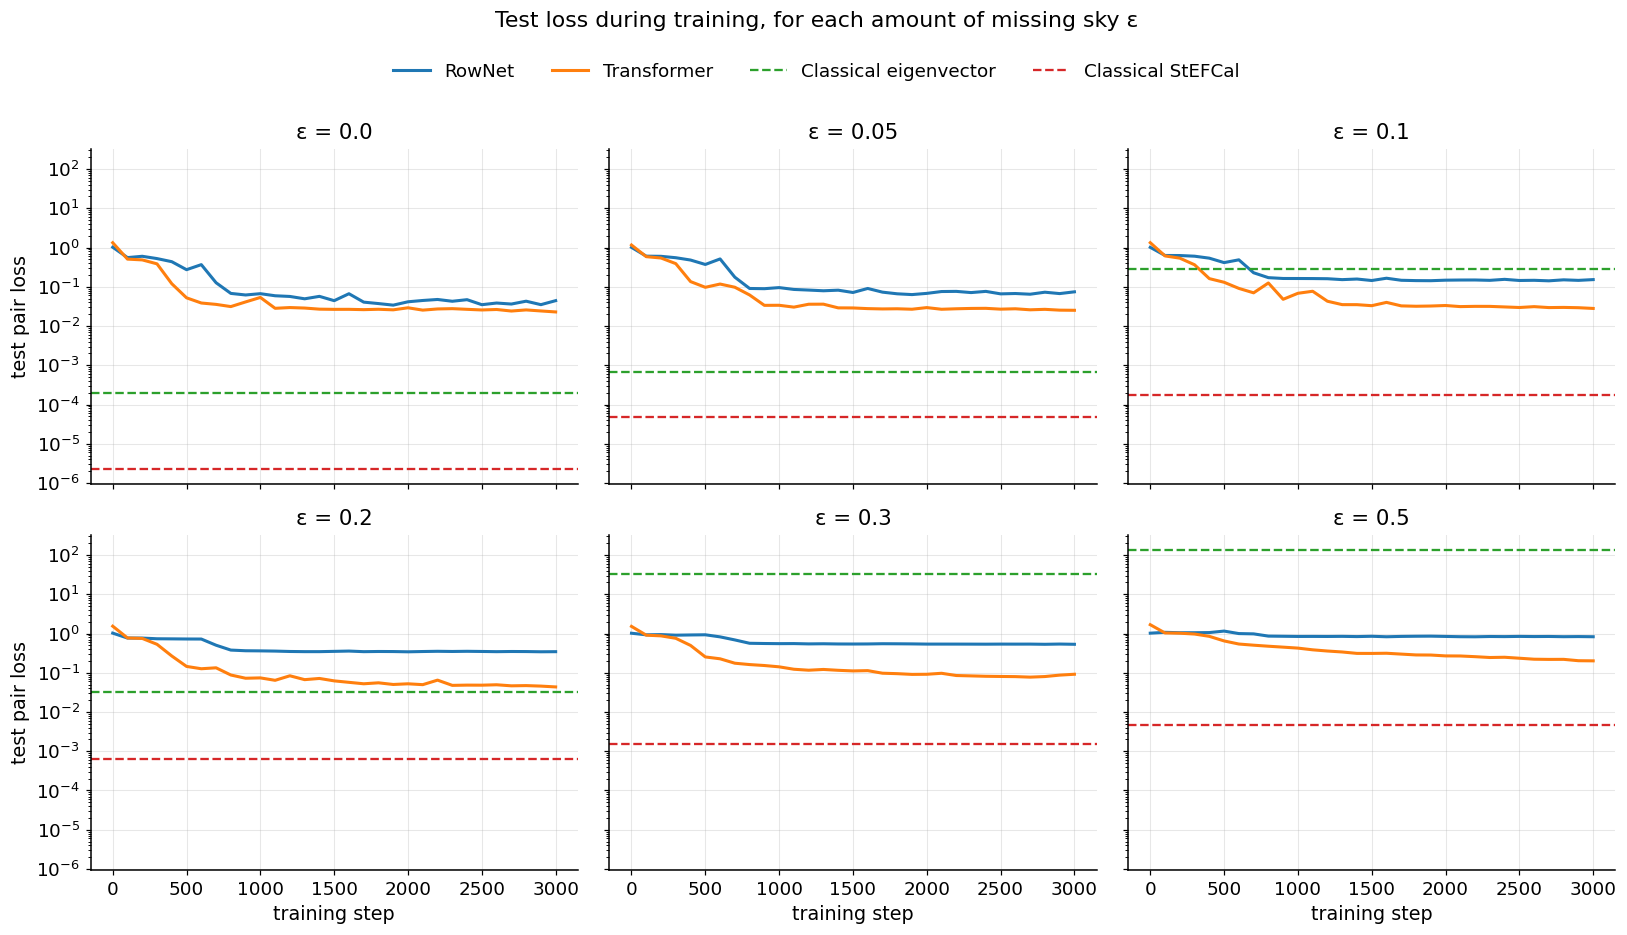

In [ ]:
# ---------- fixed test set for each epsilon (identical for every model) ----------
gen = torch.Generator(device=device).manual_seed(123)
TEST = {e: [make_batch(32, torch.full((32,), e, device=device), gen) for _ in range(2)] for e in EPS}

@torch.no_grad()
def test_loss(predict, e):
    return np.mean([pair_loss(predict(R), g, all_good(len(g))).item() for R, g in TEST[e]])

# ---------- same as your train(), but it checks the test loss at every epsilon every 100 steps ----------
def train_tracked(model, steps=3000, bs=32, lr=1e-3, seed=0, every=100):
    model.to(device).train(); opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator(device=device).manual_seed(seed)
    steps_log, log = [], {e: [] for e in EPS}
    for step in range(steps + 1):
        if step % every == 0:
            model.eval()
            for e in EPS: log[e].append(test_loss(lambda R: model(feat(R)), e))
            steps_log.append(step); model.train()
        if step == steps: break
        R, g = make_batch(bs, torch.rand(bs, generator=gen, device=device) * EPS_MAX, gen)
        loss = pair_loss(model(feat(R)), g, all_good(bs))
        opt.zero_grad(); loss.backward(); opt.step()
    return model.eval(), np.array(steps_log), log

print("training RowNet");      rownet2, steps_r, log_r = train_tracked(RowNet(), lr=1e-3)
print("training Transformer"); transformer2, steps_t, log_t = train_tracked(AntennaTransformer(), lr=3e-4)

# classical methods don't train, so they are one flat line per epsilon
stef = {e: test_loss(stefcal_from_R, e) for e in EPS}
eig  = {e: test_loss(eigen_from_R, e) for e in EPS}

# ---------- plot: one panel per epsilon ----------
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, e in zip(axs.flat, EPS):
    ax.plot(steps_r, log_r[e], color="C0", lw=2, label="RowNet")
    ax.plot(steps_t, log_t[e], color="C1", lw=2, label="Transformer")
    ax.axhline(eig[e],  color="C2", ls="--", lw=1.5, label="Classical eigenvector")
    ax.axhline(stef[e], color="C3", ls="--", lw=1.5, label="Classical StEFCal")
    ax.set_title(f"ε = {e}")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
for ax in axs[1]: ax.set_xlabel("training step")
for ax in axs[:, 0]: ax.set_ylabel("test pair loss")
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Test loss during training, for each amount of missing sky ε", y=1.06)
fig.tight_layout()
fig.savefig("loss_vs_steps_per_eps.png", dpi=300, bbox_inches="tight")
plt.show()